<div style="line-height: 1.8;">

## **eggNOG-mapper**

Для расширенной функциональной аннотации исследовали 4315 белков из каталога Bakta с помощью eggNOG-mapper. По результатам поиска получили сведения об ортологических группах, функциональных категориях и связи белков с биологическими процессами и метаболическими путями.

В таблице eggNOG учли 4224 записи; для 91 белка соответствующие результаты отсутствовали. Перед объединением проверили согласованность идентификаторов с FASTA Bakta. Исходный состав CDS и названия продуктов сохранили, а дополнительные сведения включили в отдельные поля.

</div>

In [1]:
from pathlib import Path
import pandas as pd
from io import StringIO

import os

# Ищем корень проекта при запуске из notebooks, проекта или общей рабочей папки.
configured_root = os.environ.get("GENOME_ANNOTATION_PROJECT_ROOT")
if configured_root:
    project_dir = Path(configured_root).expanduser().resolve()
else:
    candidates = [candidate for base in (Path.cwd(), *Path.cwd().parents)
                  for candidate in (base, base / "projects/genome_annotation")]
    project_dir = next((p for p in candidates if (p / "data/raw/genome.fna").is_file()), None)
if project_dir is None or not (project_dir / "data/raw/genome.fna").is_file():
    raise FileNotFoundError("Откройте ноутбук из папки проекта или задайте GENOME_ANNOTATION_PROJECT_ROOT")

file_path = (project_dir/ "results/functional/eggnog/query.emapper.annotations")

# Удаляем служебные строчки 
# А заголовок таблицы обычно начинается с #query
with open(file_path) as f:
    lines = [line for line in f if not line.startswith("##")]

eggnog_df = pd.read_csv(
    StringIO("".join(lines)),
    sep="\t",
    na_values=["-"]
)
eggnog_df.columns = eggnog_df.columns.str.lstrip("#")

print("Количество строк:", len(eggnog_df))
print("Количество столбцов:", len(eggnog_df.columns))
print("\nНазвания столбцов:")
print(eggnog_df.columns.tolist())

display(eggnog_df.head())

Количество строк: 4224
Количество столбцов: 22

Названия столбцов:
['query', 'seed_ortholog', 'evalue', 'score', 'eggNOG_OGs', 'tax_ceiling', 'farthest_donor_lineage', 'COG_category', 'Preferred_name', 'GOs', 'EC', 'KEGG_ko', 'KEGG_Pathway', 'KEGG_Module', 'KEGG_Reaction', 'KEGG_rclass', 'BRITE', 'KEGG_TC', 'CAZy', 'BiGG_Reaction', 'PFAMs', 'annotation_confidence']


,query,seed_ortholog,evalue,score,eggNOG_OGs,tax_ceiling,farthest_donor_lineage,COG_category,Preferred_name,GOs,...,KEGG_Pathway,KEGG_Module,KEGG_Reaction,KEGG_rclass,BRITE,KEGG_TC,CAZy,BiGG_Reaction,PFAMs,annotation_confidence
0,KOIAIB_01159,357240.GCA_001063355_00271,1.910000e-44,145.0,PP-binding@131567|cA-12,Prokaryota,1;131567;2;2323;1783234;1817807;3106474;1817870,COG0236,acpP,"GO:0000035,GO:0000036,GO:0005515,GO:0005737,GO...",...,"01100,01110","M00848,M00885,M00886",NaN,NaN,00001,NaN,NaN,NaN,PP-binding_6_73,mm-hhh--h---h
1,KOIAIB_03833,357240.GCA_001063355_01138,6.810000e-53,167.0,RNA_pol_Rpb6@131567|A-1,Prokaryota,1;131567;2;3379134;1783257;203682;473814;1801951,COG1758,rpoZ,"GO:0000345,GO:0001000,GO:0005829,GO:0006352,GO...",...,03020,NaN,NaN,NaN,"00001,01000,01611,03021,03400",NaN,NaN,NaN,RNA_pol_Rpb6_9_59,mmhhh---h---h
2,KOIAIB_03480,357240.GCA_001063355_01353,5.050000e-162,455.0,"KH_2@131567|O-5,Ribosomal_S3_C@131567|A-1",Prokaryota,1;131567;2;3379134;1783257;203682;203683;112;4...,COG0092,rpsC,"GO:0000028,GO:0002181,GO:0003735,GO:0005737,GO...",...,03010,NaN,NaN,NaN,"00001,01610,03011",NaN,NaN,NaN,"KH_2_38_111,Ribosomal_S3_C_120_202",mm-hh---h---h
3,KOIAIB_03477,357240.GCA_001063355_01356,1.230000e-54,171.0,Ribosomal_S17@131567|A-1,Prokaryota,1;131567;2;3379134;1783257;204428;204429;51291...,COG0186,rpsQ,"GO:0000028,GO:0002181,GO:0003735,GO:0005737,GO...",...,03010,NaN,NaN,NaN,"00001,01610,03011",NaN,NaN,NaN,Ribosomal_S17_10_76,mh-hh---h---h
4,KOIAIB_03927,357240.GCA_001063355_01707,8.350000e-44,144.0,ATP-synt_C@131567|A-1,Prokaryota,1;131567;2;1783272;201174;1760;85007;1762;6705...,COG0636,atpE,"GO:0005886,GO:0042777,GO:0045259,GO:0046933,GO...",...,"00190,01100",M00157,NaN,NaN,"00001,00194",NaN,NaN,NaN,ATP-synt_C_11_71,mm-hhh--h---h


In [2]:
from Bio import SeqIO

bakta_proteins = list(SeqIO.parse(project_dir /"results/structural/bakta/ecoli.faa", "fasta"))

bakta_ids = {p.id for p in bakta_proteins}
eggnog_ids = set(eggnog_df["query"].dropna().astype(str))

print("Белков Bakta:", len(bakta_ids))
print("Белков в таблице eggNOG:", len(eggnog_ids))
print("Совпадающих ID:", len(bakta_ids & eggnog_ids))
print("Нет в eggNOG:", len(bakta_ids - eggnog_ids))

Белков Bakta: 4315
Белков в таблице eggNOG: 4224
Совпадающих ID: 4224
Нет в eggNOG: 91


<div style="line-height: 1.8;">

### **Объединение аннотаций Bakta и eggNOG**

Из GenBank Bakta извлекли идентификаторы CDS, координаты, направление цепи и описания продуктов. Таблицу eggNOG присоединили по ключу `query` с проверкой связи «один к одному».

Левое объединение позволило сохранить все 4315 CDS, включая записи без результатов eggNOG. Повторяющихся ключей, которые привели бы к размножению строк, не обнаружили.

</div>

In [3]:
#Объединение аннотации Bakta и eggNOG
bakta_dir = project_dir / "results/structural/bakta"

genome = SeqIO.read(
    bakta_dir / "ecoli.gbff",
    "genbank"
)

bakta_data = []

for feature in genome.features:
    if feature.type != "CDS":
        continue

    bakta_data.append({
        "query": feature.qualifiers.get("locus_tag", [None])[0],
        "bakta_gene": feature.qualifiers.get("gene", [None])[0],
        "bakta_product": feature.qualifiers.get("product", [None])[0],
        "start": int(feature.location.start) + 1,
        "end": int(feature.location.end),
        "strand": feature.location.strand
    })

bakta_table = pd.DataFrame(bakta_data)

print("Совпадающих ID:", len(set(bakta_table["query"]) & eggnog_ids))

merged = bakta_table.merge(
    eggnog_df,
    on = "query",
    how = 'left',
    validate = 'one_to_one'
)

print("Всего CDS:", len(merged))

display(merged.head())

Совпадающих ID: 4224
Всего CDS: 4315


,query,bakta_gene,bakta_product,start,end,strand,seed_ortholog,evalue,score,eggNOG_OGs,...,KEGG_Pathway,KEGG_Module,KEGG_Reaction,KEGG_rclass,BRITE,KEGG_TC,CAZy,BiGG_Reaction,PFAMs,annotation_confidence
0,KOIAIB_00001,NaN,hypothetical protein,3,98,1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,KOIAIB_00002,NaN,thr operon leader peptide,190,255,1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,KOIAIB_00003,NaN,Bifunctional aspartokinase/homoserine dehydrog...,337,2799,1,585057.ECIAI39_0001,0.000000e+00,1589.0,"Homoserine_dh@131567|A-1,NAD_binding_3@131567|...",...,"00260,00261,00270,00300,01100,01110,01120,01230","M00016,M00017,M00018,M00526,M00527",NaN,NaN,"00001,01000",NaN,NaN,NaN,"AA_kinase_2_284,ACT_7_314_375,ACT_7_393_453,Ho...",hhhhhh--h---h
3,KOIAIB_00004,NaN,Homoserine kinase,2801,3733,1,511145.b0003,3.280000e-226,624.0,"GHMP_kinases_N@131567|Ap-7,GHMP_kinases_C@1315...",...,"00260,00270,01100,01110,01120,01230",M00018,NaN,NaN,"00001,01000",NaN,NaN,NaN,"GHMP_kinases_C_212_281,GHMP_kinases_N_85_150",mhhhhh--h---h
4,KOIAIB_00005,NaN,Threonine synthase,3734,5020,1,511145.b0004,5.450000e-312,850.0,"PALP@131567|HD-13!,Thr_synth_N@131567|A-1",...,"00260,00750,01100,01110,01120,01230",M00018,NaN,NaN,"00001,01000",NaN,NaN,NaN,"PALP_99_369,Thr_synth_N_8_80",hhhhhh--h---h


In [4]:
hypothetical = merged[merged["bakta_product"].fillna("").str.lower() == "hypothetical protein"].copy()

print("Hypothetical proteins Bakta:", len(hypothetical))

for column in ["Description", "GOs", "KEGG_ko", "PFAMs"]:
    if column in hypothetical.columns:
        print(
            column,
            hypothetical[column].notna().sum()
        )

Hypothetical proteins Bakta: 234
GOs 73
KEGG_ko 96
PFAMs 136


<div style="line-height: 1.8;">

Дополнительные сведения оценили по трём группам признаков: терминам Gene Ontology, функциональным ортологическим группам KEGG KO и семействам или доменам Pfam. При интерпретации учли, что среди доменов Pfam представлены и DUF — домены с неустановленной функцией.

Из 234 исходных гипотетических белков для 73 получили термины GO, для 96 — KEGG KO, для 136 — Pfam. Хотя бы один из этих типов сведений присутствовал у 153 белков; группы частично пересекались. Соответствующую выборку сохранили отдельно.

</div>

In [5]:
# Гипотетические белки с дополнительными аннотациями
columns = [
    "query",
    "bakta_gene",
    "bakta_product",
    "Description",
    "GOs",
    "KEGG_ko",
    "PFAMs"
]

available_columns = [ c for c in columns if c in hypothetical.columns]

annotated_hypothetical = hypothetical[
    hypothetical[
        [c for c in ["GOs", "KEGG_ko", "PFAMs"]
         if c in hypothetical.columns]
    ].notna().any(axis=1)
].copy()

print(
    "Hypothetical proteins с хотя бы одной аннотацией:",
    len(annotated_hypothetical)
)

display(annotated_hypothetical[available_columns].head(15))

Hypothetical proteins с хотя бы одной аннотацией: 153


,query,bakta_gene,bakta_product,GOs,KEGG_ko,PFAMs
5,KOIAIB_00006,NaN,hypothetical protein,NaN,NaN,DUF2502_25_73
12,KOIAIB_00013,NaN,hypothetical protein,NaN,NaN,DUF2541_3_132
32,KOIAIB_00036,NaN,hypothetical protein,NaN,K08277,NaN
68,KOIAIB_00075,NaN,hypothetical protein,"GO:0004857,GO:0046325",NaN,NaN
112,KOIAIB_00124,NaN,hypothetical protein,NaN,NaN,DUF3300_75_351
185,KOIAIB_00199,NaN,hypothetical protein,NaN,K19000,ROF_9_83
195,KOIAIB_00210,NaN,hypothetical protein,"GO:0005515,GO:0005886,GO:0015191,GO:0015821,GO...",K02072,BPD_transp_1_32_216
201,KOIAIB_00223,NaN,hypothetical protein,NaN,NaN,Methyltransf_11_6_96
218,KOIAIB_00242,NaN,hypothetical protein,"GO:0003674,GO:0008150",K19303,NLPC_P60_131_241
221,KOIAIB_00247,NaN,hypothetical protein,NaN,K02557,OmpA_70_163


In [6]:
output = (
    project_dir
    / "results/functional/eggnog/hypothetical_annotated.tsv"
)

annotated_hypothetical[available_columns].to_csv(
    output,
    sep="\t",
    index=False
)

<div style="line-height: 1.8;">

## **InterProScan для гипотетических белков**

Для дополнительного анализа отобрали 234 белка, отнесённых по результатам аннотации Bakta к гипотетическим. Последовательности сохранили в общем FASTA и разделили на три порции по 100, 100 и 34 белка.

Подготовленные порции использовали во внешнем запуске InterProScan. В последующем анализе обработали три сохранённых ответа TSV.

</div>

In [7]:
from Bio import SeqIO

hypothetical_ids = set(hypothetical["query"]) #айдишники 
selected_proteins = [
    protein
    for protein in bakta_proteins
    if protein.id in hypothetical_ids
]

output = (
    project_dir
    / "results/functional/interpro/hypothetical.faa"
)

output.parent.mkdir(parents=True, exist_ok=True)

SeqIO.write(selected_proteins, output, "fasta")

print("Белков для InterPro:", len(selected_proteins))

Белков для InterPro: 234


In [8]:
# Для этого запуска использовали порции по 100 белков.
batch_size = 100

for i, start in enumerate(range(0, len(selected_proteins), batch_size), start=1):
    batch = selected_proteins[start:start + batch_size]

    batch_path = output.parent / f"hypothetical_batch_{i}.faa"

    SeqIO.write(batch, batch_path, "fasta")

    print(batch_path.name, len(batch))

hypothetical_batch_1.faa 100
hypothetical_batch_2.faa 100
hypothetical_batch_3.faa 34


<div style="line-height: 1.8;">

### **Идентичные белковые последовательности в первой порции**

При проверке первой порции установили, что 100 идентификаторам соответствовали 98 уникальных аминокислотных последовательностей. Обнаружили две пары идентичных белков: `KOIAIB_00018` / `KOIAIB_00628` и `KOIAIB_01281` / `KOIAIB_01285`.

Пары относились к разным геномным локусам. Поэтому отдельные записи сохранили, а совпадение последовательностей учли при переносе результатов доменного анализа.

</div>

In [9]:
from collections import Counter

batch_path = (project_dir/ "results/functional/interpro/hypothetical_batch_1.faa")

records = list(SeqIO.parse(batch_path, "fasta"))

ids = [r.id for r in records]
seqs = [str(r.seq).upper() for r in records]

print("Всего последовательностей:", len(records))
print("Уникальных ID:", len(set(ids)))
print("Уникальных последовательностей:", len(set(seqs)))

print("\nПовторяющиеся последовательности:")
for seq, n in Counter(seqs).items():
    if n > 1:
        print(
            "Количество:", n,
            "ID:", [r.id for r in records if str(r.seq).upper() == seq]
        )


Всего последовательностей: 100
Уникальных ID: 100
Уникальных последовательностей: 98

Повторяющиеся последовательности:
Количество: 2 ID: ['KOIAIB_00018', 'KOIAIB_00628']
Количество: 2 ID: ['KOIAIB_01281', 'KOIAIB_01285']


In [10]:
duplicate_ids = [
    "KOIAIB_00018",
    "KOIAIB_00628",
    "KOIAIB_01281",
    "KOIAIB_01285"
]

display(
    merged.loc[
        merged["query"].isin(duplicate_ids),
        [
            "query",
            "bakta_gene",
            "start",
            "end",
            "strand",
            "bakta_product"
        ]
    ]
)

,query,bakta_gene,start,end,strand,bakta_product
16,KOIAIB_00018,NaN,16580,16720,1,hypothetical protein
572,KOIAIB_00628,NaN,609200,609340,1,hypothetical protein
1186,KOIAIB_01281,NaN,1269168,1269275,-1,hypothetical protein
1188,KOIAIB_01285,NaN,1270238,1270345,-1,hypothetical protein


<div style="line-height: 1.8;">

### **InterPro analysis result**

</div>

<div style="line-height: 1.8;">

В трёх файлах InterProScan учли 2206 строк совпадений, относящихся к 208 идентификаторам белков. Сведения сгруппировали по ID, поскольку одному белку могли соответствовать несколько сигнатур и участков совпадения.

Интегрированные записи InterPro с идентификатором IPR рассматривали отдельно от остальных сигнатур. Число строк TSV не использовали как число белков с установленной функцией.

</div>

In [11]:
# Читаем три сохранённых результата InterProScan.
interpro_dir = project_dir / "results/functional/interpro"

files = sorted(interpro_dir.glob("result_interPro_*.tsv"))


columns = [
    "protein_id",
    "sequence_md5",
    "protein_length",
    "analysis",
    "signature_accession",
    "signature_description",
    "start",
    "end",
    "score",
    "status",
    "date",
    "interpro_accession",
    "interpro_description",
    "go_terms",
    "pathways"
]

interpro_df = pd.concat(
    [
        pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=columns,
            dtype=str,
            na_values=["-"]
        )
        for file in files
    ],
    ignore_index=True
)

print("Всего найденных совпадений:", len(interpro_df))
print(
    "Уникальных белков с совпадениями:",
    interpro_df["protein_id"].nunique()
)

display(interpro_df.head())
interpro_df["sequence_md5"] = interpro_df["sequence_md5"].str.upper()

Всего найденных совпадений: 2206
Уникальных белков с совпадениями: 208


,protein_id,sequence_md5,protein_length,analysis,signature_accession,signature_description,start,end,score,status,date,interpro_accession,interpro_description,go_terms,pathways
0,KOIAIB_01554,013B75228E761953F44B2ED5C5299238,306,CATH-Gene3D,G3DSA:3.80.10.10,Ribonuclease Inhibitor,61,304,2.7E-32,CATH-Gene3D,23-10-2026,IPR032675,Leucine-rich repeat domain superfamily,NaN,Reactome:R-MMU-9758274|Reactome:R-DDI-1660517|...
1,KOIAIB_01554,013B75228E761953F44B2ED5C5299238,306,PANTHER,PTHR46652,LEUCINE-RICH REPEAT AND IQ DOMAIN-CONTAINING P...,141,288,2.1E-12,PANTHER,23-10-2026,IPR050836,SDS22/Internalin LRR-containing,NaN,Reactome:R-HSA-380259|Reactome:R-HSA-380284|Re...
2,KOIAIB_01554,013B75228E761953F44B2ED5C5299238,306,Pfam,PF00560,Leucine Rich Repeat,21,34,850.0,Pfam,23-10-2026,IPR001611,Leucine-rich repeat,GO:0005515(InterPro),Reactome:R-MMU-9758274|Reactome:R-DDI-1660517|...
3,KOIAIB_01554,013B75228E761953F44B2ED5C5299238,306,Pfam,PF00560,Leucine Rich Repeat,184,197,1000.0,Pfam,23-10-2026,IPR001611,Leucine-rich repeat,GO:0005515(InterPro),Reactome:R-MMU-9758274|Reactome:R-DDI-1660517|...
4,KOIAIB_01554,013B75228E761953F44B2ED5C5299238,306,Pfam,PF00560,Leucine Rich Repeat,205,226,4700.0,Pfam,23-10-2026,IPR001611,Leucine-rich repeat,GO:0005515(InterPro),Reactome:R-MMU-9758274|Reactome:R-DDI-1660517|...


In [12]:
#Агрегация по protein_id
def unique_values(series):
    values = sorted({
        str(value)
        for value in series.dropna()
        if str(value).strip()
    })
    return "; ".join(values) if values else None


interpro_summary = (
    interpro_df.groupby("protein_id")
    .agg(
        interpro_ids=(
            "interpro_accession", unique_values
        ),
        interpro_domains=(
            "interpro_description", unique_values
        ),
        signatures=(
            "signature_accession", unique_values
        ),
        interpro_go=(
            "go_terms", unique_values
        ),
        analyses=(
            "analysis", unique_values
        )
    )
    .reset_index()
    .rename(columns={"protein_id": "query"})
)

print('Всего белков :', len(interpro_summary))
display(interpro_summary.head())

Всего белков :

 208


,query,interpro_ids,interpro_domains,signatures,interpro_go,analyses
0,KOIAIB_00006,IPR019638,Protein of unknown function DUF2502,NON_CYTOPLASMIC_DOMAIN; PF10697; SIGNAL_PEPTID...,NaN,MobiDB-lite; Pfam; Phobius; SignalP
1,KOIAIB_00013,IPR020240,"Uncharacterised protein family UPF0412, YaaI",MF_01372; NF007541; NON_CYTOPLASMIC_DOMAIN; PF...,NaN,HAMAP; NCBIFAM; Pfam; Phobius; SignalP
2,KOIAIB_00036,IPR020357; IPR036388,Transcription regulator CaiF/GrlA; Winged heli...,G3DSA:1.10.10.10; G3DSA:1.10.10.10:FF:000309; ...,GO:0006351(InterPro),CATH-FunFam; CATH-Gene3D; NCBIFAM; Pfam
3,KOIAIB_00059,NaN,NaN,PTHR35282,NaN,PANTHER
4,KOIAIB_00075,IPR031767,Inhibitor of glucose uptake transporter SgrT,PF15894,GO:0046325(InterPro),Pfam


<div style="line-height: 1.8;">

### **Учёт идентичных белков: MD5-хеширование**

Для каждой отправленной последовательности рассчитали MD5 и сопоставили его со значением из ответа InterProScan. Проверили принадлежность хешей исходному набору и соответствие длин белков.

Результаты сгруппировали по MD5, после чего присоединили к каждому соответствующему ID Bakta. Такой способ сопоставления позволил учесть одинаковые белки из разных локусов без потери отдельных CDS. В исследованном наборе 234 идентификаторам соответствовала 231 уникальная последовательность.

</div>

In [13]:
import hashlib

protein_mapping = pd.DataFrame([
    {
        "query": protein.id,
        "sequence_md5": hashlib.md5(
            str(protein.seq).upper().encode("ascii")
        ).hexdigest().upper()
    }
    for protein in selected_proteins
])

display(protein_mapping.head())

print("Всего белков:", len(protein_mapping))
print(
    "Уникальных последовательностей:",
    protein_mapping["sequence_md5"].nunique()
)

submitted_lengths = {hashlib.md5(str(p.seq).upper().encode("ascii")).hexdigest().upper(): len(p.seq)
                     for p in selected_proteins}
assert interpro_df.sequence_md5.isin(submitted_lengths).all(), "InterPro содержит неизвестные последовательности"
assert (interpro_df.protein_length.astype(int) == interpro_df.sequence_md5.map(submitted_lengths)).all()

,query,sequence_md5
0,KOIAIB_00001,85DA80F888567F99BBE143E35A201FAE
1,KOIAIB_00006,ACCD217A526DB58F0DC94FAD2625013A
2,KOIAIB_00013,D612BBF7EE4E74B80A7A6E2D0DB5C40E
3,KOIAIB_00018,6BCB0203C5C58D2E0087E0C1848E82FF
4,KOIAIB_00036,61D804F5E6839C42806F4D4E18FD3C6D


Всего белков: 234
Уникальных последовательностей: 231


In [14]:
#Агрегация по MD5-хэшу из interpro_df
interpro_summary_md5 = (
    interpro_df.groupby("sequence_md5")
    .agg(
        interpro_ids=("interpro_accession", unique_values),
        interpro_domains=("interpro_description", unique_values),
        signatures=("signature_accession", unique_values),
        interpro_go=("go_terms", unique_values),
        analyses=("analysis", unique_values)
    )
    .reset_index()
)

print(
    "Уникальных последовательностей с совпадениями:",
    len(interpro_summary_md5)
)
display(interpro_summary_md5.head(10))

Уникальных последовательностей с совпадениями:

 207


,sequence_md5,interpro_ids,interpro_domains,signatures,interpro_go,analyses
0,00926371A557641DC94145AD2FAFEE4B,IPR010279; IPR043604; IPR043605,"DUF883, C-terminal domain; DUF883, N-terminal ...",CYTOPLASMIC_DOMAIN; Coil; NF007709; NON_CYTOPL...,GO:0043022(InterPro),COILS; NCBIFAM; PANTHER; Pfam; Phobius
1,013B75228E761953F44B2ED5C5299238,IPR001611; IPR032675; IPR050836,Leucine-rich repeat; Leucine-rich repeat domai...,G3DSA:3.80.10.10; PF00560; PR00019; PS51450; P...,GO:0005515(InterPro),CATH-Gene3D; PANTHER; PRINTS; PROSITE profiles...
2,03B2426A05727E7A5026ADB045E3127E,IPR050900,Transposase IS3/IS150/IS904,PF13276; PTHR46889,NaN,PANTHER; Pfam
3,03F335E35199E40F9E8B0E271EDFBC87,IPR036770,Ankyrin repeat-containing domain superfamily,G3DSA:1.25.40.20; PTHR24121; SSF48403,NaN,CATH-Gene3D; PANTHER; SUPERFAMILY
4,086ED0D9565AABC8B397E8711026D30C,IPR021728,Protein of unknown function DUF3300,NON_CYTOPLASMIC_DOMAIN; PF11737; PTHR40269; SI...,NaN,MobiDB-lite; PANTHER; Pfam; Phobius
5,08DE24EA625185059FA88F56695D2BC8,IPR009778; IPR023534; IPR038626,Modulator of Rho-dependent transcription termi...,G3DSA:2.30.30.400; G3DSA:2.30.30.400:FF:000001...,NaN,CATH-FunFam; CATH-Gene3D; NCBIFAM; Pfam; SUPER...
6,09278CF194481E021676AD58C442C483,NaN,NaN,G3DSA:2.30.30.110; PF01845; SSF50118,NaN,CATH-Gene3D; Pfam; SUPERFAMILY
7,09A0F6DED4E9199676621C48B1B3C0A7,IPR057653,YeeW-like domain,PF19419; PF25638,NaN,Pfam
8,0A0D6C82D7A0B19716A7ABFD2E205FDD,IPR008593,DNA N-6-adenine-methyltransferase,G3DSA:3.40.50.150; PF05869; TIGR01712,GO:0003677(InterPro)|GO:0009007(InterPro)|GO:0...,CATH-Gene3D; NCBIFAM; Pfam
9,0A28D7AE39527D24630C9E7CF321E1CE,IPR048192; IPR059488,Small membrane protein YldA; YoaI/YldA-like,CYTOPLASMIC_DOMAIN; NF041476; NON_CYTOPLASMIC_...,NaN,NCBIFAM; Pfam; Phobius


In [15]:
#Восстановление аннотации
interpro_complete = protein_mapping.merge(
    interpro_summary_md5,
    on="sequence_md5",
    how="left",
    validate="many_to_one"
)

print("Всего белков:", len(interpro_complete))

print(
    "Белков с InterPro ID:",
    interpro_complete["interpro_ids"].notna().sum()
)

display(interpro_complete.head())

Всего белков: 234
Белков с InterPro ID: 166


,query,sequence_md5,interpro_ids,interpro_domains,signatures,interpro_go,analyses
0,KOIAIB_00001,85DA80F888567F99BBE143E35A201FAE,NaN,NaN,NaN,NaN,NaN
1,KOIAIB_00006,ACCD217A526DB58F0DC94FAD2625013A,IPR019638,Protein of unknown function DUF2502,NON_CYTOPLASMIC_DOMAIN; PF10697; SIGNAL_PEPTID...,NaN,MobiDB-lite; Pfam; Phobius; SignalP
2,KOIAIB_00013,D612BBF7EE4E74B80A7A6E2D0DB5C40E,IPR020240,"Uncharacterised protein family UPF0412, YaaI",MF_01372; NF007541; NON_CYTOPLASMIC_DOMAIN; PF...,NaN,HAMAP; NCBIFAM; Pfam; Phobius; SignalP
3,KOIAIB_00018,6BCB0203C5C58D2E0087E0C1848E82FF,NaN,NaN,NaN,NaN,NaN
4,KOIAIB_00036,61D804F5E6839C42806F4D4E18FD3C6D,IPR020357; IPR036388,Transcription regulator CaiF/GrlA; Winged heli...,G3DSA:1.10.10.10; G3DSA:1.10.10.10:FF:000309; ...,GO:0006351(InterPro),CATH-FunFam; CATH-Gene3D; NCBIFAM; Pfam


In [16]:
duplicate_ids = [
    "KOIAIB_00018",
    "KOIAIB_00628",
    "KOIAIB_01281",
    "KOIAIB_01285"
]

display(
    interpro_complete.loc[
        interpro_complete["query"].isin(duplicate_ids),
        ["query", "sequence_md5", "interpro_ids", "interpro_domains"]
    ]
)

,query,sequence_md5,interpro_ids,interpro_domains
3,KOIAIB_00018,6BCB0203C5C58D2E0087E0C1848E82FF,NaN,NaN
39,KOIAIB_00628,6BCB0203C5C58D2E0087E0C1848E82FF,NaN,NaN
75,KOIAIB_01281,0DC3E987EAB4546D4CC5B2C564A7E27F,IPR025253,"Type I toxin-antitoxin system, toxin Ldr"
77,KOIAIB_01285,0DC3E987EAB4546D4CC5B2C564A7E27F,IPR025253,"Type I toxin-antitoxin system, toxin Ldr"


<div style="line-height: 1.8;">

Для белков `KOIAIB_01281` и `KOIAIB_01285` установили совпадение с семейством Ldr. На этом основании рассмотрели их как кандидатов на белковые компоненты токсин-антитоксинных систем I типа. Наличие соответствующей антитоксиновой РНК и функциональную активность системы в данном анализе не подтверждали.

</div>

<div style="line-height: 1.8;">

### **Объединённый функциональный каталог**

Сводные результаты InterPro присоединили к таблице Bakta и eggNOG по идентификатору `query`. Итоговый каталог сохранили в `results/integrated/ecoli_complete_annotation.tsv`; в нём учли 4315 CDS и 32 поля аннотации.

</div>

In [17]:
final_annotation = merged.merge(
    interpro_complete.drop(columns="sequence_md5"),
    on="query",
    how="left",
    validate="one_to_one"
)

print("Количество CDS:", len(final_annotation))
print("Количество столбцов:", len(final_annotation.columns))

display(final_annotation.head())

output = project_dir / "results/integrated/ecoli_complete_annotation.tsv"
output.parent.mkdir(parents=True, exist_ok=True)
final_annotation.to_csv(output, sep="\t", index=False)
print("Сохранено:", output.relative_to(project_dir))

Количество CDS: 4315
Количество столбцов: 32


,query,bakta_gene,bakta_product,start,end,strand,seed_ortholog,evalue,score,eggNOG_OGs,...,KEGG_TC,CAZy,BiGG_Reaction,PFAMs,annotation_confidence,interpro_ids,interpro_domains,signatures,interpro_go,analyses
0,KOIAIB_00001,NaN,hypothetical protein,3,98,1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,KOIAIB_00002,NaN,thr operon leader peptide,190,255,1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,KOIAIB_00003,NaN,Bifunctional aspartokinase/homoserine dehydrog...,337,2799,1,585057.ECIAI39_0001,0.000000e+00,1589.0,"Homoserine_dh@131567|A-1,NAD_binding_3@131567|...",...,NaN,NaN,NaN,"AA_kinase_2_284,ACT_7_314_375,ACT_7_393_453,Ho...",hhhhhh--h---h,NaN,NaN,NaN,NaN,NaN
3,KOIAIB_00004,NaN,Homoserine kinase,2801,3733,1,511145.b0003,3.280000e-226,624.0,"GHMP_kinases_N@131567|Ap-7,GHMP_kinases_C@1315...",...,NaN,NaN,NaN,"GHMP_kinases_C_212_281,GHMP_kinases_N_85_150",mhhhhh--h---h,NaN,NaN,NaN,NaN,NaN
4,KOIAIB_00005,NaN,Threonine synthase,3734,5020,1,511145.b0004,5.450000e-312,850.0,"PALP@131567|HD-13!,Thr_synth_N@131567|A-1",...,NaN,NaN,NaN,"PALP_99_369,Thr_synth_N_8_80",hhhhhh--h---h,NaN,NaN,NaN,NaN,NaN


Сохранено: results/integrated/ecoli_complete_annotation.tsv


<div style="line-height: 1.8;">

### **Дополнительные сведения для белков без GO, KEGG KO и Pfam**

После обработки результатов eggNOG выделили 81 исходный гипотетический белок без значений GO, KEGG KO и Pfam. Для этой группы отдельно оценили наличие интегрированных записей IPR и других сигнатур в результатах InterProScan.

</div>

In [18]:
remaining = final_annotation[
    final_annotation["bakta_product"]
    .fillna("")
    .str.lower()
    .eq("hypothetical protein")
    &
    final_annotation[
        ["GOs", "KEGG_ko", "PFAMs"]
    ].isna().all(axis=1)
].copy()

print("Без GO/KEGG/Pfam eggNOG:", len(remaining))

print(
    "С InterPro ID:",
    remaining["interpro_ids"].notna().sum()
)

print(
    "С любой сигнатурой InterProScan:",
    remaining["signatures"].notna().sum()
)

Без GO/KEGG/Pfam eggNOG: 81
С InterPro ID: 24
С любой сигнатурой InterProScan: 57


<div style="line-height: 1.8;">

## **Вывод по ноутбуку**

Для 24 из 81 белка получили интегрированные записи IPR, ещё для 33 — другие сигнатуры. Для оставшихся 24 белков совпадений в сохранённых результатах InterProScan не зарегистрировали. При объединении обоих этапов дополнительные признаки учли у 210 из 234 исходных гипотетических белков.

Полученный охват не приравнивали к числу белков с установленной функцией: например, сигнатуры неупорядоченных участков характеризовали особенности структуры, но не определяли биологическую роль. Анализ InterProScan ограничили исходными гипотетическими белками; для остальных CDS этот поиск не проводили.

</div>

<div style="line-height: 1.8;">

### **Охват дополнительной функциональной аннотацией**

На рисунке отразили накопление дополнительных сведений для 234 исходных гипотетических белков: 153 записи после анализа eggNOG и 210 после учёта сигнатур InterProScan. Начальный ноль обозначал отсутствие этих дополнительных признаков до рассматриваемых этапов, а не отсутствие аннотации Bakta в целом.

</div>

<div style="line-height: 1.8;">

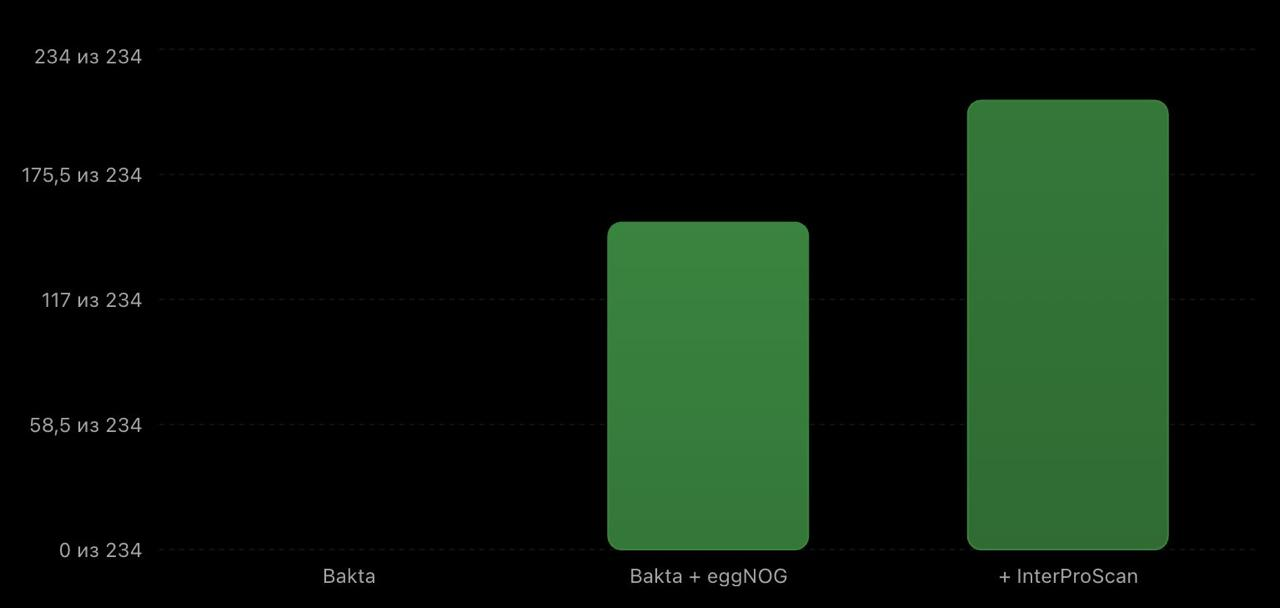

</div>